# Detailed HR Model Comparison (Test Set)

Comparison of four heart-rate estimation models across six activities.

**Source:** previously computed, user-reported per-activity test results from notebooks 03–06. Values below are **rounded** to two decimals (percentages also to two decimals). These graphs visualize existing results; they do **not** retrain any model or re-calculate predictions.

- **MAE:** lower is better.
- **Within ±5 BPM / ±10 BPM:** percentage of test windows with absolute HR error at most 5 / 10 BPM; higher is better. These are tolerance-based hit rates, *not* classification accuracy.
- The six activity sample sizes are unequal. Eating has only 8 test windows; interpret its percentages carefully.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ACTIVITIES = ["Eating", "High Tempo Cycling", "Low Tempo Cycling", "Sitting", "Sleep", "Walking"]
MODELS = ["PPG-only CNN", "Early Fusion CNN", "Two-Branch CNN", "CNN + BiGRU"]
SAMPLES = [8, 38, 56, 43, 73, 74]

# Values transcribed from the actual notebook tables (03–06); rounded to 2 decimals.
values = {
    "PPG-only CNN": {
        "MAE (BPM)": [14.27,12.67,10.60,9.28,13.27,5.22],
        "Within ±5 BPM (%)": [50.00,28.95,30.36,32.56,2.74,56.76],
        "Within ±10 BPM (%)": [62.50,52.63,44.64,60.47,24.66,89.19],
    },
    "Early Fusion CNN": {
        "MAE (BPM)": [8.89,9.25,5.34,3.86,3.71,3.91],
        "Within ±5 BPM (%)": [25.00,23.68,46.43,76.74,75.34,81.08],
        "Within ±10 BPM (%)": [75.00,63.16,87.50,93.02,100.00,94.59],
    },
    "Two-Branch CNN": {
        "MAE (BPM)": [10.13,9.23,5.09,3.49,1.35,3.71],
        "Within ±5 BPM (%)": [50.00,34.21,62.50,76.74,100.00,81.08],
        "Within ±10 BPM (%)": [62.50,63.16,85.71,95.35,100.00,94.59],
    },
    "CNN + BiGRU": {
        "MAE (BPM)": [5.23,8.63,4.35,3.96,1.46,3.22],
        "Within ±5 BPM (%)": [50.00,31.58,58.93,81.40,100.00,86.49],
        "Within ±10 BPM (%)": [100.00,73.68,96.43,95.35,100.00,95.95],
    },
}

rows=[]
for model in MODELS:
    for i, activity in enumerate(ACTIVITIES):
        rows.append({"Model":model,"Activity":activity,"Test windows":SAMPLES[i],
                     **{metric: values[model][metric][i] for metric in values[model]}})
results=pd.DataFrame(rows)
display(results)


,Model,Activity,Test windows,MAE (BPM),Within ±5 BPM (%),Within ±10 BPM (%)
0,PPG-only CNN,Eating,8,14.27,50.00,62.50
1,PPG-only CNN,High Tempo Cycling,38,12.67,28.95,52.63
2,PPG-only CNN,Low Tempo Cycling,56,10.60,30.36,44.64
3,PPG-only CNN,Sitting,43,9.28,32.56,60.47
4,PPG-only CNN,Sleep,73,13.27,2.74,24.66
5,PPG-only CNN,Walking,74,5.22,56.76,89.19
6,Early Fusion CNN,Eating,8,8.89,25.00,75.00
7,Early Fusion CNN,High Tempo Cycling,38,9.25,23.68,63.16
8,Early Fusion CNN,Low Tempo Cycling,56,5.34,46.43,87.50
9,Early Fusion CNN,Sitting,43,3.86,76.74,93.02


In [2]:
# Save a machine-readable comparison table.
# Run from notebooks/ inside the project, or from the project root.
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
fig_dir = root / "results" / "figures"
metric_dir = root / "results" / "metrics"
fig_dir.mkdir(parents=True, exist_ok=True)
metric_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(metric_dir / "hr_model_activity_comparison_rounded.csv", index=False)
print("CSV:", metric_dir / "hr_model_activity_comparison_rounded.csv")


CSV: c:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\metrics\hr_model_activity_comparison_rounded.csv


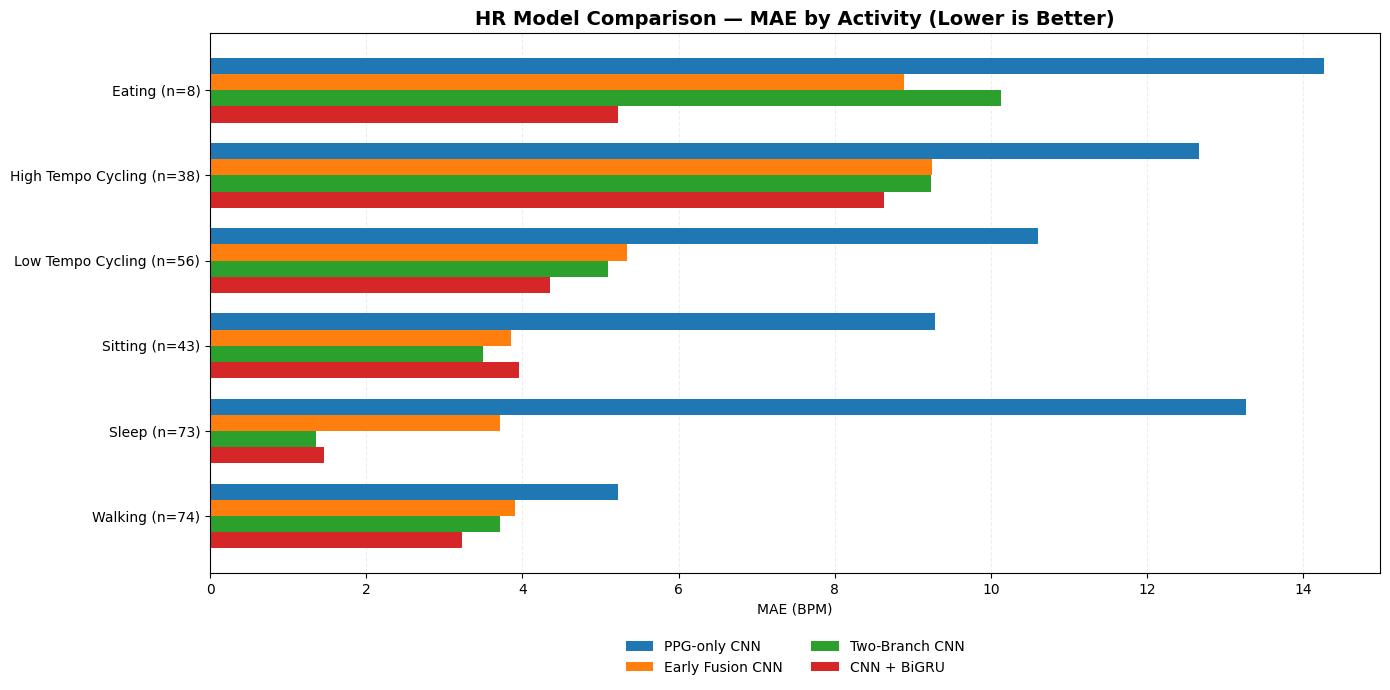

Saved: c:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\figures\hr_four_models_per_activity_mae.png


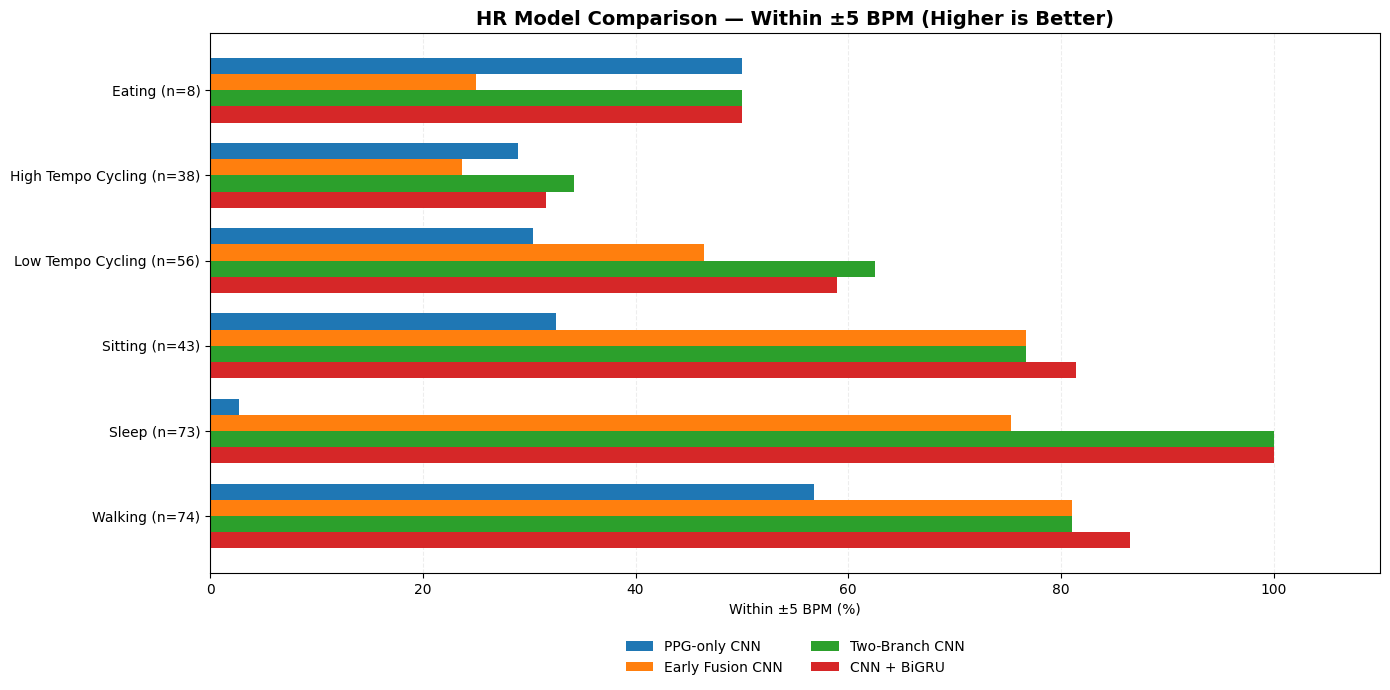

Saved: c:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\figures\hr_four_models_per_activity_within5.png


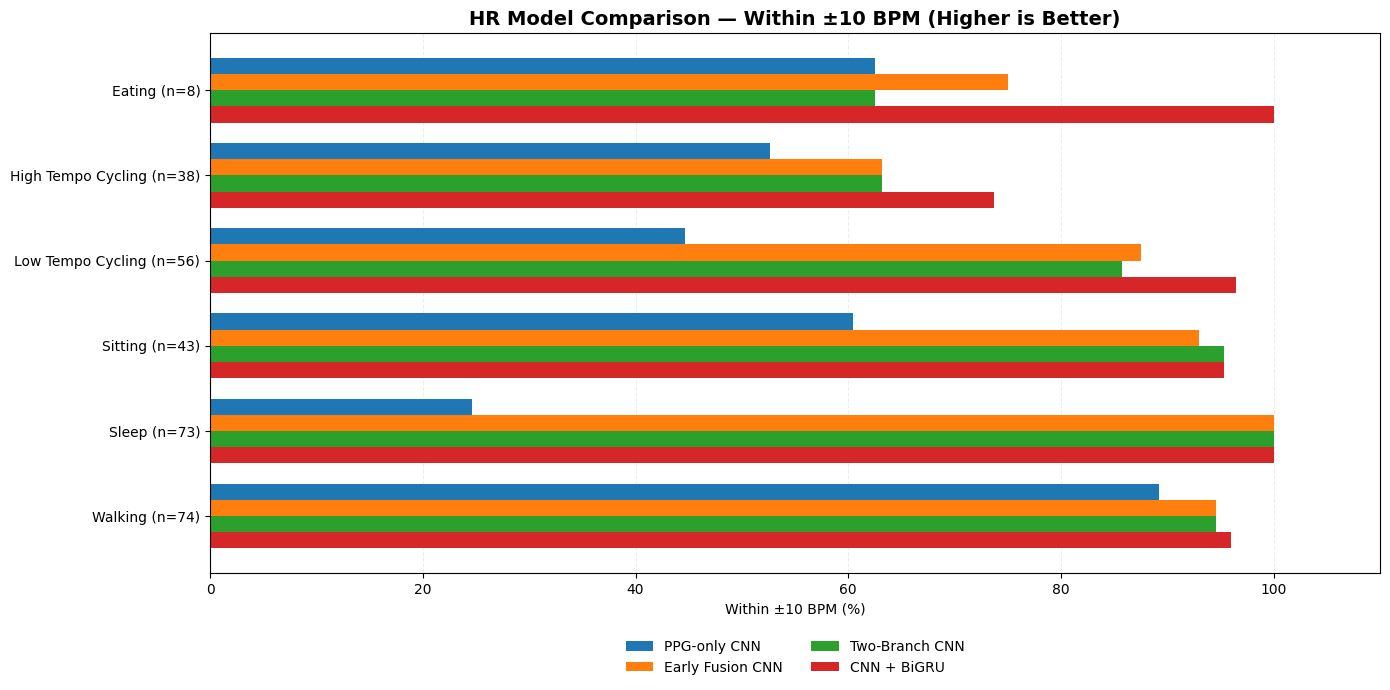

Saved: c:\Users\MONSTER PC\Desktop\PPG-IMU-HR-Estimation-DeepLearning\results\figures\hr_four_models_per_activity_within10.png


In [3]:
def plot_comparison(metric, filename, title, percent=False):
    fig, ax = plt.subplots(figsize=(14, 7))
    y = np.arange(len(ACTIVITIES))
    bar_h = 0.19
    # One group of 4 horizontal bars per activity.
    for j, model in enumerate(MODELS):
        series = results.loc[results["Model"] == model].set_index("Activity").loc[ACTIVITIES, metric]
        ax.barh(y + (j - 1.5) * bar_h, series.values, height=bar_h,
                label=model)
    labels = [f"{a} (n={size})" for a,size in zip(ACTIVITIES,SAMPLES)]
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel(metric)
    ax.set_title(title, fontsize=14, weight="bold")
    if percent:
        ax.set_xlim(0, 110)
        ax.set_xticks(np.arange(0, 101, 20))
    else:
        ax.set_xlim(left=0)
    ax.grid(axis="x", alpha=.22, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(.5,-.10), ncol=2, frameon=False)
    fig.tight_layout()
    out=fig_dir / filename
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:",out)

plot_comparison("MAE (BPM)", "hr_four_models_per_activity_mae.png",
                "HR Model Comparison — MAE by Activity (Lower is Better)")
plot_comparison("Within ±5 BPM (%)", "hr_four_models_per_activity_within5.png",
                "HR Model Comparison — Within ±5 BPM (Higher is Better)", percent=True)
plot_comparison("Within ±10 BPM (%)", "hr_four_models_per_activity_within10.png",
                "HR Model Comparison — Within ±10 BPM (Higher is Better)", percent=True)


## Brief interpretation

- The **CNN + BiGRU** has the best **overall** MAE (3.865 BPM), but it is **not best on every activity**.
- **Two-Branch CNN** has the lowest MAE for *Sitting* (3.49 BPM) and *Sleep* (1.35 BPM).
- **CNN + BiGRU** has the lowest MAE for *Eating*, both cycling activities, and *Walking*.
- The high-tempo cycling MAE remains comparatively high for all four models.
- The ±5/±10 BPM proportions do **not** replace MAE/RMSE or show time-varying tracking quality. Per-activity R² and correlation should also be discussed.
- These visualizations use rounded values from prior output tables; for final publication, saving full-precision window-level predictions and computing results from those arrays would provide better traceability.
